# Scraping Berita Saham - Detik Finance (REVISI)
## 7 Emiten LQ45 Sektor Energi | Periode: Januari 2022 - Mei 2026

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45) - XGBoost & LSTM
**Penulis**: Ilda Nurida (NRP 6032251068) | **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Ringkasan perbaikan

| # | Masalah lama | Perbaikan |
|---|---|---|
| 1 | **False positive "sebutan sekilas"**: roundup IHSG yang menyebut ticker 1x dalam daftar rekomendasi tersimpan sebagai berita emiten | F4 biner diganti **skor relevansi prominence** (emiten di judul / frekuensi / posisi sebutan) |
| 2 | Roundup pasar ("IHSG Hari Ini", "Rekomendasi Saham") mencemari label emiten | Filter **headline roundup**: dibuang bila emiten tak disebut di judul |
| 3 | Keyword generik ("ADRO bursa", "PGAS emiten") boroskan fetch & surfacing artikel generik | Keyword **dipendekkan** (recall via nama, presisi via skor) |
| 4 | `content_detik` tanpa fallback -> body kosong di sebagian artikel | **Auto-deteksi selector body** + fallback klaster `<p>` |

**Dipertahankan (sudah bagus)**: parser tanggal tangguh (relatif + bulan Indonesia), tanggal dari listing, mekanisme search `siteid=2`, stop `all_old`.

> **PENTING**: jalankan **Bagian 6 (Probe)** sebelum Bagian 8.

## 1. Install Library

In [2]:
!pip install -q tqdm requests beautifulsoup4 lxml pandas
print("Library berhasil diinstall")

Library berhasil diinstall



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Library & Konfigurasi

In [3]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup as bs
from datetime import datetime, timedelta, timezone
import time, random, re
import pandas as pd
from pathlib import Path
from tqdm import tqdm

WIB = timezone(timedelta(hours=7))
start_date = datetime(2022, 1, 1, tzinfo=WIB)
end_date   = datetime(2026, 6, 30, 23, 59, 59, tzinfo=WIB)

OUTPUT_DIR     = Path('../../03_dataset/raw')
CHECKPOINT_DIR = Path('checkpoint_detik')
for d in (OUTPUT_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / 'berita_detik_lq45_energi.csv'
BASE_URL    = 'https://www.detik.com'

print("Konfigurasi siap")
print(f"Periode : {start_date:%d %B %Y} s/d {end_date:%d %B %Y}")
print(f"Output  : {OUTPUT_FILE}")

Konfigurasi siap
Periode : 01 January 2022 s/d 30 June 2026
Output  : ..\..\03_dataset\raw\berita_detik_lq45_energi.csv


## 3. Daftar 7 Emiten, Keyword (dipendekkan), & Alias

In [4]:
# Keyword pendek -> recall tinggi. Presisi diserahkan ke skor prominence.
EMITEN = {
    'ADRO': ['Adaro Energy', 'Alamtri', 'Adaro'],
    'ADMR': ['Adaro Minerals'],
    'ITMG': ['Indo Tambangraya', 'ITMG'],
    'PTBA': ['Bukit Asam', 'PTBA'],
    'MEDC': ['Medco Energi', 'Medco'],
    'AKRA': ['AKR Corporindo'],
    'PGAS': ['Perusahaan Gas Negara', 'PGN', 'PGAS'],
}
EMITEN_ALIAS = {
    'ADRO': ['adaro energy', 'adaro', 'alamtri', 'adro'],
    'ADMR': ['adaro minerals', 'admr'],
    'ITMG': ['indo tambangraya', 'tambangraya', 'itmg'],
    'PTBA': ['bukit asam', 'ptba'],
    'MEDC': ['medco energi', 'medco', 'medc'],
    'AKRA': ['akr corporindo', 'akra'],
    'PGAS': ['perusahaan gas negara', 'pgas', 'pgn'],
}
NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk', 'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk', 'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk', 'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}
URUTAN_EMITEN = list(EMITEN.keys())
print(f"Total emiten: {len(EMITEN)}")
for k in URUTAN_EMITEN:
    print(f"  {k}: {EMITEN[k]}")

Total emiten: 7
  ADRO: ['Adaro Energy', 'Alamtri', 'Adaro']
  ADMR: ['Adaro Minerals']
  ITMG: ['Indo Tambangraya', 'ITMG']
  PTBA: ['Bukit Asam', 'PTBA']
  MEDC: ['Medco Energi', 'Medco']
  AKRA: ['AKR Corporindo']
  PGAS: ['Perusahaan Gas Negara', 'PGN', 'PGAS']


## 4. Filter F1-F2 & Skor Relevansi Prominence (pengganti F3-F4)

**Inti perbaikan.** `skor_relevansi()` memutuskan apakah artikel benar-benar
*tentang* emiten, bukan sekadar menyebutnya sekilas:
1. Emiten disebut **di judul** -> kuat, simpan.
2. Judul berpola **roundup pasar** (IHSG/rekomendasi saham) tanpa emiten di judul -> buang.
3. Selain itu: butuh emiten disebut >=2x di isi, ATAU 1x tapi di **lede** (<=600 char awal).

In [5]:
# ══════════════════════════════════════════════════════════════════════════
# FIX AUDIT — PENCOCOKAN ALIAS DENGAN BATAS KATA (WORD BOUNDARY)
# ══════════════════════════════════════════════════════════════════════════
# Versi lama memakai substring polos (`alias in teks`) sehingga alias pendek
# ikut cocok di dalam kata lain: 'pgn' cocok pada "pgnXYZ", 'itm' pada
# "itmxyz", 'akr' pada "akronim". Akibatnya banyak berita BUMN/Pertamina
# umum ikut tersimpan sebagai PGAS (false positive). Tiga fungsi di bawah
# menggantikannya dengan pencocokan KATA UTUH.
# ══════════════════════════════════════════════════════════════════════════
import re as _re

def _sebut(alias_list, teks):
    """True bila salah satu alias muncul sebagai KATA UTUH di `teks`."""
    for a in alias_list:
        a = str(a).strip()
        if a and _re.search(rf'(?<!\w){_re.escape(a)}(?!\w)', teks):
            return True
    return False

def _hitung_sebut(alias_list, teks):
    """Jumlah kemunculan alias sebagai kata utuh (maksimum antar alias)."""
    return max((len(_re.findall(rf'(?<!\w){_re.escape(str(a).strip())}(?!\w)', teks))
                for a in alias_list if str(a).strip()), default=0)

def _posisi_sebut(alias_list, teks):
    """Posisi karakter kemunculan pertama alias sebagai kata utuh (1e9 bila nihil)."""
    kandidat = []
    for a in alias_list:
        a = str(a).strip()
        if not a:
            continue
        m = _re.search(rf'(?<!\w){_re.escape(a)}(?!\w)', teks)
        if m:
            kandidat.append(m.start())
    return min(kandidat) if kandidat else 10**9


KATEGORI_BUANG_URL = ['/travel/', '/food/', '/wolipop/', '/health/', '/sport/',
    '/hot/', '/inet/', '/oto/', '/foto/', '20.detik.com', '/pemilu/',
    '/edu/', '/hikmah/', '/x-sport/', '/detikpop/', '/creativespot/']
def filter_url(link):
    l = str(link).lower()
    return not any(k in l for k in KATEGORI_BUANG_URL)

KATA_BUANG_HEADLINE = ['wisata', 'liburan', 'destinasi', 'kuliner', 'resep',
    'restoran', 'makanan', 'cafe', 'kafe', 'fashion', 'kecantikan', 'skincare',
    'film', 'artis', 'seleb', 'gosip', 'musik', 'konser', 'drakor', 'bola',
    'liga', 'pertandingan', 'turnamen', 'atlet', 'horoskop', 'zodiak',
    'tips kesehatan', 'diet', 'penyakit', 'vaksin', 'resep masakan']
def filter_headline(headline):
    h = str(headline).lower()
    return not any(k in h for k in KATA_BUANG_HEADLINE)

# Pola judul roundup pasar (menyebut banyak ticker, bukan tentang 1 emiten)
GENERIC_HEADLINE = re.compile(
    r'\b(ihsg|rekomendasi saham|saham pilihan|cek saham|sederet saham|'
    r'deretan saham|daftar saham|top gainers|top losers|saham hari ini|'
    r'watchlist|portofolio|saham.{0,12}cuan|saham.{0,12}untung|'
    r'jelang pembukaan|pra[- ]?pembukaan|sesi i)\b', re.I)

KATA_KONTEKS_SAHAM = ['saham', 'bursa', 'bei', 'idx', 'ihsg', 'emiten', 'investor',
    'laba', 'rugi', 'pendapatan', 'revenue', 'kinerja', 'keuangan', 'kuartal',
    'dividen', 'buyback', 'merger', 'akuisisi', 'ipo', 'rights issue',
    'target harga', 'rekomendasi', 'analis', 'sekuritas', 'valuasi',
    'harga saham', 'menguat', 'melemah', 'produksi', 'batubara', 'batu bara',
    'minyak', 'gas', 'lifting', 'ekspor', 'laba bersih', 'rupst', 'capex']

def skor_relevansi(kode, headline, isi):
    '''Return (bool, alasan). Prominence-based; mengganti F3+F4 biner.'''
    alias = EMITEN_ALIAS.get(kode, [kode.lower()])
    hl, bl = str(headline).lower(), str(isi).lower()

    # konteks pasar minimal harus ada (F3)
    if not any(k in (hl + ' ' + bl) for k in KATA_KONTEKS_SAHAM):
        return False, 'tanpa_konteks_pasar'

    in_headline = _sebut(alias, hl)
    if in_headline:
        return True, 'emiten_di_judul'

    if GENERIC_HEADLINE.search(headline):
        return False, 'roundup_tanpa_emiten_di_judul'

    n = _hitung_sebut(alias, bl)
    if n >= 2:
        return True, f'emiten_{n}x_di_isi'
    if n == 1:
        pos = _posisi_sebut(alias, bl)
        if pos <= 600:
            return True, 'emiten_di_lede'
    return False, 'sebutan_sekilas'

print("Filter F1-F2 & skor_relevansi() siap")

Filter F1-F2 & skor_relevansi() siap


## 5. Session, Parser Tanggal (tangguh), Ekstraktor Body

In [6]:
USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:124.0) Gecko/20100101 Firefox/124.0',
]
def get_headers(referer='https://finance.detik.com/'):
    return {'User-Agent': random.choice(USER_AGENTS),
            'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
            'Accept-Language': 'id-ID,id;q=0.9,en-US;q=0.8,en;q=0.7', 'Referer': referer}
def buat_session():
    # FIX AUDIT: 429 SENGAJA TIDAK masuk status_forcelist. Bila 429 ditangani
    # urllib3 (backoff_factor=2) DAN loop manual safe_get() sekaligus, jedanya
    # berlipat -> run bisa macet berjam-jam. Rate-limit ditangani SEPENUHNYA
    # oleh safe_get() di bawah.
    s = requests.Session()
    retry = Retry(total=4, backoff_factor=2, status_forcelist=[500, 502, 503, 504])  # FIX AUDIT: 429 dihapus

    s.mount('https://', HTTPAdapter(max_retries=retry))
    return s
sess = buat_session()
def safe_get(url, timeout=25, max_retry=3, referer='https://finance.detik.com/'):
    global sess
    for attempt in range(1, max_retry + 1):
        try:
            r = sess.get(url, headers=get_headers(referer), timeout=timeout)
            if r.status_code == 429:
                wait = 60 * attempt
                print(f"  Rate-limit 429 - tunggu {wait}s..."); time.sleep(wait)
                sess = buat_session(); continue
            return r
        except requests.exceptions.ConnectionError as e:
            print(f"  ConnectionError ({attempt}/{max_retry}): {str(e)[:60]}")
            time.sleep(10 * attempt); sess = buat_session()
        except requests.exceptions.Timeout:
            time.sleep(5 * attempt)
        except Exception as e:
            print(f"  Error: {e}"); return None
    return None

BULAN = {'Januari':'Jan','Februari':'Feb','Maret':'Mar','April':'Apr','Mei':'May',
         'Juni':'Jun','Juli':'Jul','Agustus':'Aug','September':'Sep','Oktober':'Oct',
         'November':'Nov','Desember':'Dec'}
HARI = {'Senin':'Mon','Selasa':'Tue','Rabu':'Wed','Kamis':'Thu','Jumat':'Fri',
        'Sabtu':'Sat','Minggu':'Sun'}
def parse_date(raw):
    if not raw: return None
    s = re.sub(r'\s+', ' ', str(raw).strip())
    s = re.sub(r'^[A-Za-z]+,\s*', '', s)  # buang "Market |"-style prefix bila ada
    m = re.match(r'^(\d+)\s+(menit|jam|hari)\s+lalu', s, re.I)
    if m:
        n, unit = int(m.group(1)), m.group(2).lower()
        now = datetime.now(WIB)
        if 'menit' in unit: return now - timedelta(minutes=n)
        if 'jam'   in unit: return now - timedelta(hours=n)
        if 'hari'  in unit: return now - timedelta(days=n)
    for indo, eng in BULAN.items():
        s = re.sub(rf'\b{indo}\b', eng, s, flags=re.I)
    for indo, eng in HARI.items():
        s = s.replace(indo, eng)
    iso = re.search(r'(\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}[+-]\d{2}:?\d{2})', s)
    if iso:
        try: return datetime.fromisoformat(iso.group(1))
        except ValueError: pass
    s = re.sub(r'\b(GMT|UTC|WIB|EST|PST|IST)\b', '', s).strip()
    for fmt in ['%a %d %b %Y %H:%M', '%a, %d %b %Y %H:%M', '%d %b %Y %H:%M',
                '%d %B %Y %H:%M', '%d/%m/%Y %H:%M', '%Y-%m-%dT%H:%M:%S',
                '%Y-%m-%d %H:%M:%S', '%d %b %Y', '%d %B %Y', '%Y-%m-%d']:
        try:
            dt = datetime.strptime(s.strip(), fmt)
            return dt if dt.tzinfo else dt.replace(tzinfo=WIB)
        except ValueError:
            continue
    return None

NOISE = ['ADVERTISEMENT', 'SCROLL TO RESUME CONTENT', 'SCROLL TO CONTINUE WITH CONTENT',
         'Simak Video', 'Baca juga:', 'BACA JUGA:', 'Baca Juga', 'NEXT ARTICLE',
         'Artikel Berikutnya']
def clean_text(text):
    for n in NOISE:
        text = text.replace(n, '')
    text = re.sub(r'\(Foto:.*?\)', '', text)
    text = re.sub(r'\([a-z]{2,3}/[a-z]{2,3}\)', '', text)   # kode redaksi (ara/ara)
    return re.sub(r'\s{2,}', ' ', text).strip()

BODY_SELECTORS = ['div.detail__body-text.itp_bodycontent', 'div.detail__body-text',
                  'div.itp_bodycontent', 'article.detail__body', 'div.detail-text',
                  'div[itemprop="articleBody"]']
DETECTED_BODY_SEL = None
def content_detik(url):
    global DETECTED_BODY_SEL
    r = safe_get(url, referer='https://finance.detik.com/')
    if not r: return ''
    soup = bs(r.text, 'lxml')
    sels = ([DETECTED_BODY_SEL] if DETECTED_BODY_SEL else []) + BODY_SELECTORS
    for sel in sels:
        if not sel: continue
        div = soup.select_one(sel)
        if div:
            txt = clean_text(' '.join(p.get_text(strip=True) for p in div.find_all('p')))
            if len(txt) > 200:
                return txt
    allp = [p.get_text(strip=True) for p in soup.find_all('p')]
    return clean_text(' '.join(p for p in allp if len(p) > 40))

print("Session, parser tanggal, ekstraktor body siap")

Session, parser tanggal, ekstraktor body siap


## 6. PROBE: Validasi Struktur Search & Auto-deteksi Selector Body

In [7]:
def build_search(kw, page):
    return (f'{BASE_URL}/search/searchall?query={requests.utils.quote(kw)}'
            f'&siteid=2&page={page}')

def parse_listing(soup):
    '''Ambil [(link, title, date_raw)] dari hasil search Detik.'''
    out = []
    for art in soup.find_all('article', class_='list-content__item'):
        try:
            link = art.find('a')['href']
            title = art.find('h3', class_='media__title').get_text(strip=True)
            date_raw = art.find('div', class_='media__date').get_text(strip=True)
        except (TypeError, AttributeError):
            # fallback: struktur alternatif
            a = art.find('a', href=True)
            if not a: continue
            link = a['href']
            h = art.find(['h2', 'h3'])
            title = h.get_text(strip=True) if h else ''
            d = art.find('div', class_=re.compile('date'))
            date_raw = d.get_text(strip=True) if d else ''
        if link and title:
            out.append((link, title, date_raw))
    return out

print("=== TES STRUKTUR SEARCH ===")
r = safe_get(build_search('Adaro Energy', 1))
print("Status:", r.status_code if r else 'GAGAL')
listing = parse_listing(bs(r.text, 'lxml')) if r else []
print(f"Artikel terdeteksi di hal 1: {len(listing)}")
for link, title, draw in listing[:4]:
    print(f"  - {title[:55]:55} | {draw} | {parse_date(draw)}")

print("\n=== UJI SELECTOR BODY ===")
if listing:
    soup_a = bs(safe_get(listing[0][0]).text, 'lxml')
    best, best_n = None, 0
    for sel in BODY_SELECTORS:
        div = soup_a.select_one(sel)
        n = len(' '.join(p.get_text(strip=True) for p in div.find_all('p'))) if div else 0
        if n > best_n: best, best_n = sel, n
        print(f"  {sel:42}: {n:5d}{'  <-' if n > 400 else ''}")
    if best_n > 400:
        DETECTED_BODY_SEL = best
        print(f"  -> Body selector: '{best}' ({best_n} char)")
    else:
        print("  -> Fallback klaster <p>.")

=== TES STRUKTUR SEARCH ===
Status: 200
Artikel terdeteksi di hal 1: 12
  - IMPC Terbang 21% dan Pasang Target 2026, TEBE Siapkan D | Kamis, 02 Apr 2026 08:48 WIB | 2026-04-02 08:48:00+07:00
  - Prabowo Minta Teknologi Olah Sampah Skala Kecil di Ting | Rabu, 11 Feb 2026 18:56 WIB | 2026-02-11 18:56:00+07:00
  - Prabowo Panggil Para Konglomerat ke Hambalang, Ada Praj | Rabu, 11 Feb 2026 08:19 WIB | 2026-02-11 08:19:00+07:00
  - Inovasi Energi Terbarukan Solusi Berkelanjutan untuk Kr | Rabu, 15 Jul 2026 07:11 WIB | 2026-07-15 07:11:00+07:00

=== UJI SELECTOR BODY ===
  div.detail__body-text.itp_bodycontent     :  3733  <-
  div.detail__body-text                     :  3733  <-
  div.itp_bodycontent                       :  3733  <-
  article.detail__body                      :     0
  div.detail-text                           :     0
  div[itemprop="articleBody"]               :     0
  -> Body selector: 'div.detail__body-text.itp_bodycontent' (3733 char)


## 7. Scraper Utama

In [8]:
def scrape_detik(kode, keywords, max_pages=300, d_min=1.5, d_max=3.5,
                 checkpoint_dir=CHECKPOINT_DIR):
    checkpoint_file = checkpoint_dir / f'{kode}_checkpoint.csv'
    if checkpoint_file.exists():
        df_ckpt = pd.read_csv(checkpoint_file, encoding='utf-8-sig')
        results = df_ckpt.to_dict('records')
        seen    = set(df_ckpt['Link'].tolist())
        print(f"  Resume checkpoint: {len(results)} artikel")
    else:
        results, seen = [], set()

    stat = dict(kandidat=0, lolos_f1=0, lolos_f2=0, disimpan=0,
                out_of_range=0, body_kosong=0, roundup=0, sekilas=0, duplikat=0)

    for kw in keywords:
        print(f'  Keyword [{kode}]: "{kw}"')
        stop = False
        for pg in range(1, max_pages + 1):
            if stop: break
            if pg % 50 == 0:
                time.sleep(random.uniform(25, 45))
            r = safe_get(build_search(kw, pg))
            if not r:
                time.sleep(random.uniform(d_min, d_max)); continue
            listing = parse_listing(bs(r.text, 'lxml'))
            if not listing:
                print(f'    Hal {pg}: tidak ada artikel -> stop keyword'); break

            all_old = True
            for link, title, date_raw in tqdm(listing, desc=f'    [{kode}] h{pg}',
                                              unit='art', leave=False):
                stat['kandidat'] += 1
                if link in seen:
                    stat['duplikat'] += 1; continue
                dt = parse_date(date_raw)
                if not dt:
                    # FIX AUDIT: tanggal GAGAL DIBACA != artikel lama.
                    # Versi lama membiarkan all_old tetap True sehingga satu
                    # halaman dgn tanggal tak terparse menghentikan paginasi
                    # terlalu dini (penyebab ITMG hanya 10 artikel).
                    all_old = False
                    continue
                if dt >= start_date:
                    all_old = False
                if not (start_date <= dt <= end_date):
                    stat['out_of_range'] += 1; continue
                if not filter_url(link):
                    seen.add(link); continue
                stat['lolos_f1'] += 1
                if not filter_headline(title):
                    seen.add(link); continue
                stat['lolos_f2'] += 1

                time.sleep(random.uniform(d_min, d_max))
                body = content_detik(link)
                seen.add(link)
                if not body.strip():
                    stat['body_kosong'] += 1; continue

                ok, alasan = skor_relevansi(kode, title, body)
                if not ok:
                    if alasan == 'roundup_tanpa_emiten_di_judul': stat['roundup'] += 1
                    elif alasan == 'sebutan_sekilas':             stat['sekilas'] += 1
                    continue

                results.append({'Sumber': 'Detik Finance', 'Kode_Emiten': kode,
                                'Keyword': kw, 'Headline': title,
                                'Tanggal': dt.strftime('%Y-%m-%d %H:%M'),
                                'Link': link, 'Isi_Berita': body})
                stat['disimpan'] += 1
                tqdm.write(f'    [{stat["disimpan"]}] {title[:68]}')
                if stat['disimpan'] % 25 == 0:
                    pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

            if all_old:
                print(f'    Hal {pg}: semua artikel < {start_date:%d %b %Y} -> stop')
                stop = True
            time.sleep(random.uniform(d_min, d_max))

    if results:
        pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')
    print(f'\n  STATISTIK [{kode}]  ' + '-'*28)
    for k, v in stat.items():
        print(f'    {k:14}: {v:>6,}')
    print(f'    (roundup+sekilas = false-positive yang berhasil dibuang)')
    return results

print("scrape_detik() siap")

scrape_detik() siap


## 8. Jalankan Scraping Semua Emiten

In [9]:
assert 'DETECTED_BODY_SEL' in dir(), "Jalankan PROBE (Bagian 6) lebih dulu!"

semua_artikel = []
mulai = datetime.now(WIB)
for kode, kws in EMITEN.items():
    print("\n" + "=" * 65)
    print(f"  {kode} | Detik Finance | {len(kws)} keyword | Mulai {datetime.now(WIB):%H:%M:%S}")
    print("=" * 65)
    hasil = scrape_detik(kode, kws)
    semua_artikel.extend(hasil)
    df_tmp = pd.DataFrame(semua_artikel).drop_duplicates(subset=['Link', 'Kode_Emiten'])
    df_tmp.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
    print(f"  Auto-save: {len(df_tmp):,} artikel | {(datetime.now(WIB)-mulai).total_seconds()/60:.1f} mnt")
    time.sleep(random.uniform(10, 18))

df_final = pd.DataFrame(semua_artikel).drop_duplicates(subset=['Link', 'Kode_Emiten']).reset_index(drop=True)
df_final.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print("\n" + "=" * 65)
print(f"  SELESAI | {(datetime.now(WIB)-mulai).total_seconds()/60:.1f} menit | {len(df_final):,} artikel")
print("=" * 65)
if len(df_final):
    print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())


  ADRO | Detik Finance | 3 keyword | Mulai 07:11:23
  Resume checkpoint: 196 artikel
  Keyword [ADRO]: "Adaro Energy"


    [ADRO] h17:  10%|█         | 1/10 [00:03<00:35,  3.91s/art]

    [1] Ini 20 Perusahaan Pembayar Pajak Terbesar di Indonesia 2023


    [ADRO] h17:  20%|██        | 2/10 [00:07<00:30,  3.75s/art]

    [2] Daftar 20 Kerajaan Bisnis Pembayar Pajak Terbesar Tahun 2023


    [ADRO] h17:  30%|███       | 3/10 [00:10<00:23,  3.32s/art]

... (600 outputs left out)

    [150] Kejati DKI Tetapkan 3 Orang Tersangka di Kasus Korupsi PT GAS Soluti


    [PGAS] h7:  36%|███▋      | 4/11 [00:06<00:10,  1.48s/art]

    [151] Kejari Jakpus Tahan 3 Tersangka Korupsi Pembangunan Sarana Pendukung


    Hal 9: semua artikel < 01 Jan 2022 -> stop

  STATISTIK [PGAS]  ----------------------------
    kandidat      :  2,870
    lolos_f1      :  1,908
    lolos_f2      :  1,871
    disimpan      :    151
    out_of_range  :     71
    body_kosong   :      6
    roundup       :      2
    sekilas       :  1,705
    duplikat      :    266
    (roundup+sekilas = false-positive yang berhasil dibuang)
  Auto-save: 1,286 artikel | 149.2 mnt

  SELESAI | 149.4 menit | 1,286 artikel
Kode_Emiten
ADRO    228
ADMR     47
ITMG     46
PTBA    300
MEDC    221
AKRA     52
PGAS    392


## 9. Rekap & Validasi Prominence

In [10]:
if 'df_final' not in dir() or df_final is None or len(df_final) == 0:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
print(f"Total artikel  : {len(df_final):,}")
print(f"Rentang tanggal: {df_final['Tanggal'].min():%Y-%m-%d} s/d {df_final['Tanggal'].max():%Y-%m-%d}")
print("\nPer emiten:")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())
print("\nPer tahun x emiten:")
print(pd.crosstab(df_final['Tanggal'].dt.year, df_final['Kode_Emiten']).reindex(columns=URUTAN_EMITEN, fill_value=0).to_string())

# Proporsi artikel yang menyebut emiten di JUDUL (indikator kualitas)
def _di_judul(row):
    hl = str(row['Headline']).lower()
    return any(a in hl for a in EMITEN_ALIAS.get(row['Kode_Emiten'], []))
p = df_final.apply(_di_judul, axis=1).mean()
print(f"\nProporsi emiten disebut di judul: {p:.0%} (makin tinggi makin presisi)")

Total artikel  : 1,286
Rentang tanggal: 2022-01-01 s/d 2026-06-30

Per emiten:
Kode_Emiten
ADRO    228
ADMR     47
ITMG     46
PTBA    300
MEDC    221
AKRA     52
PGAS    392

Per tahun x emiten:
Kode_Emiten  ADRO  ADMR  ITMG  PTBA  MEDC  AKRA  PGAS
Tanggal                                              
2022           71    12    18    88    73    19   103
2023           26     8     2    53    47    11    66
2024           73    10    18    65    36    12    66
2025           39     5     4    72    42     8    99
2026           19    12     4    22    23     2    58

Proporsi emiten disebut di judul: 27% (makin tinggi makin presisi)


## 10. Simpan Output dengan Kolom Standar

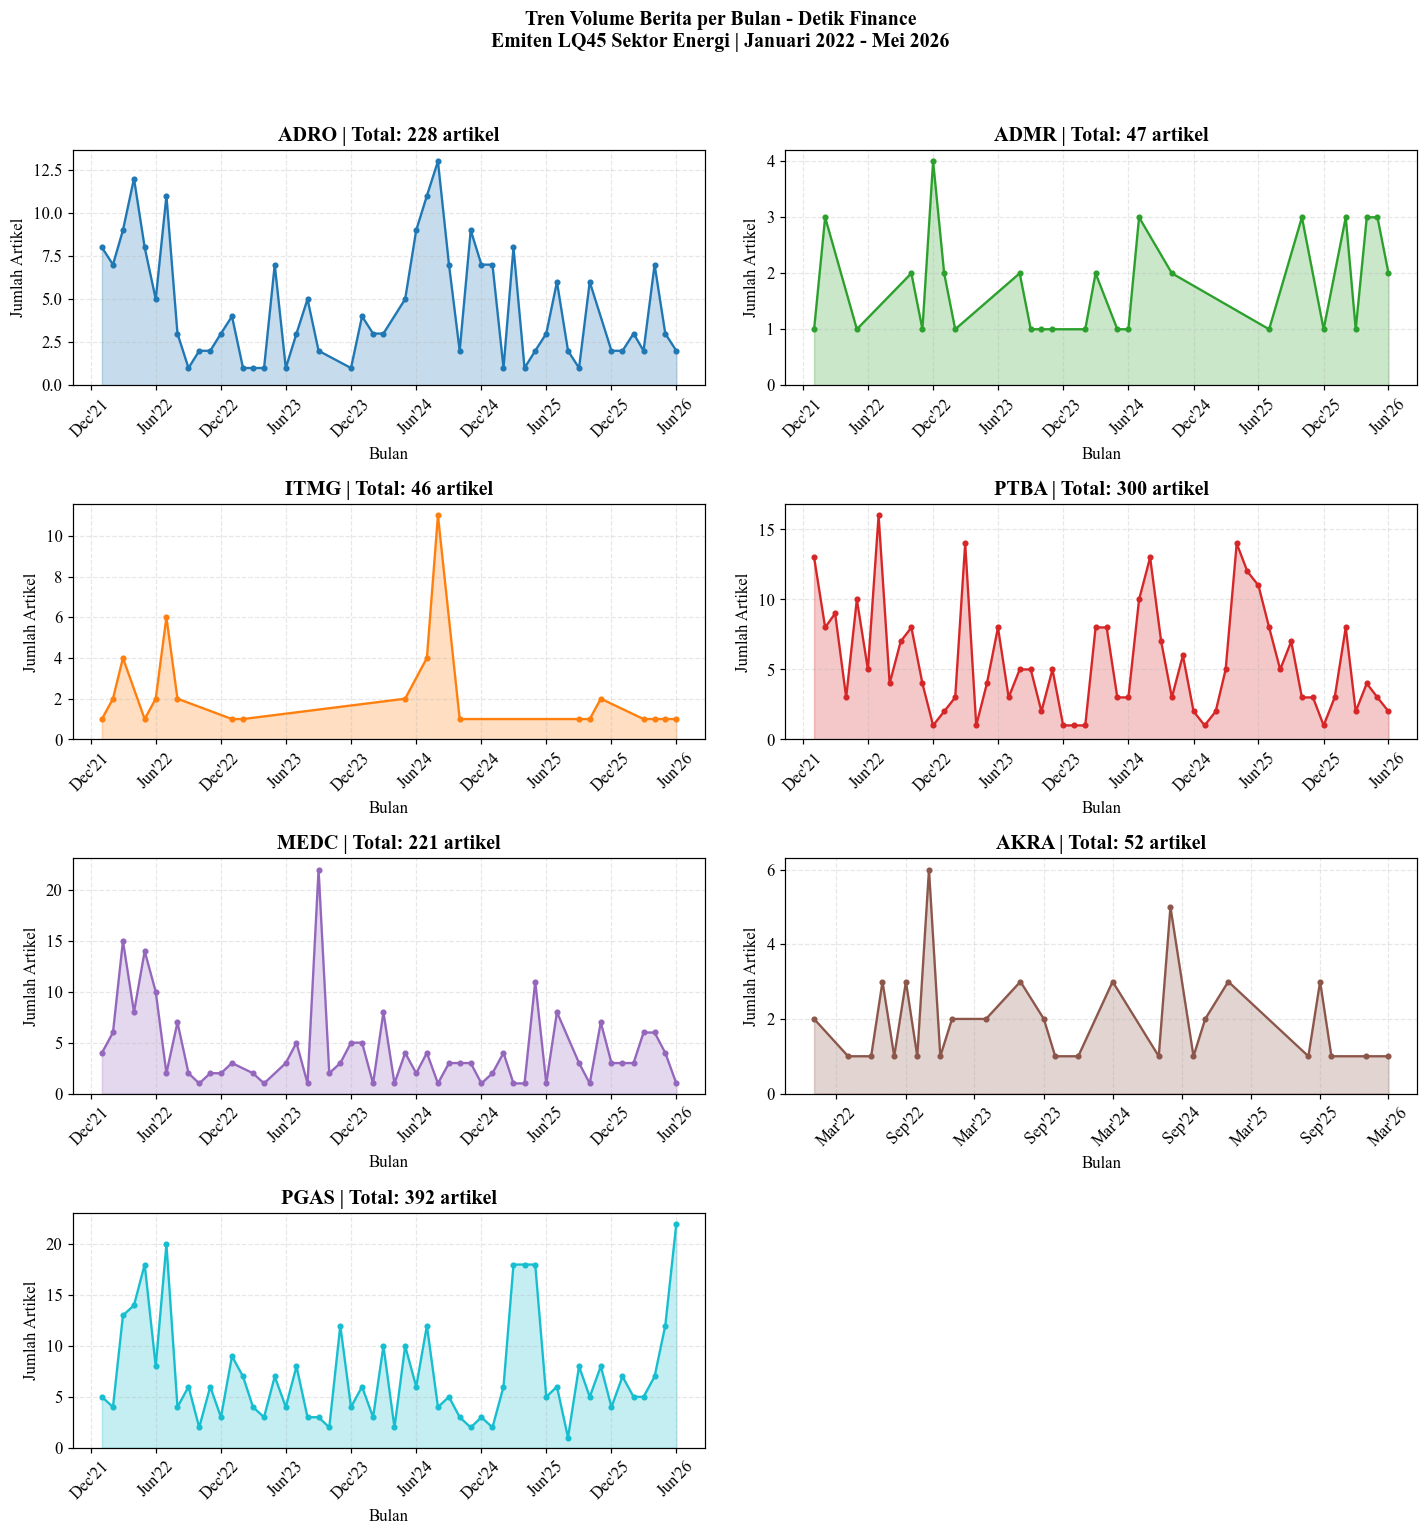

Gambar disimpan: ..\..\03_dataset\dashboard\tren_berita_detik_per_emiten.png


In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'font.family': 'Times New Roman', 'font.size': 11, 'figure.dpi': 110,
})

WARNA = {
    'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
    'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf',
}

df_final['Bulan_str'] = df_final['Tanggal'].dt.to_period('M').astype(str)
df_bul = df_final.groupby(['Bulan_str', 'Kode_Emiten']).size().reset_index(name='Jumlah')
df_bul['Bulan_dt'] = pd.to_datetime(df_bul['Bulan_str'])

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    d  = df_bul[df_bul['Kode_Emiten'] == kode].sort_values('Bulan_dt')

    if len(d) > 0:
        ax.fill_between(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], alpha=0.25)
        ax.plot(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode],
                linewidth=1.5, marker='o', markersize=3)

    total = int(d['Jumlah'].sum()) if len(d) > 0 else 0
    ax.set_title(f"{kode} | Total: {total} artikel", fontweight='bold')
    ax.set_xlabel('Bulan')
    ax.set_ylabel('Jumlah Artikel')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_ylim(bottom=0)

axes[-1].axis('off')

fig.suptitle('Tren Volume Berita per Bulan - Detik Finance\n'
              'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
              fontsize=13, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])

# Definisikan folder output untuk dashboard/plot
OUTPUT_DIR_DASHBOARD = OUTPUT_DIR.parent / 'dashboard'
OUTPUT_DIR_DASHBOARD.mkdir(parents=True, exist_ok=True)

path_gambar = OUTPUT_DIR_DASHBOARD / 'tren_berita_detik_per_emiten.png'
fig.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_gambar}")

## 11. Simpan Output dengan Kolom Standar

File disimpan dengan kolom standar agar konsisten dengan output scraping
Kontan dan Bisnis.com (untuk digabung pada tahap preprocessing sentimen IndoBERT).


In [13]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']

df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')

for k in KOLOM_STANDAR:
    if k not in df_final.columns:
        df_final[k] = ''

df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].copy()
df_save.drop_duplicates(subset=['Link', 'Kode_Emiten'], inplace=True)
df_save.reset_index(drop=True, inplace=True)

df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')

print("=" * 65)
print(f"File diperbarui dengan kolom standar: {OUTPUT_FILE}")
print(f"  Total artikel final : {len(df_save):,}")
print(f"  Kolom : {list(df_save.columns)}")
print()
print("LANGKAH SELANJUTNYA:")
print("  -> Jalankan scraping Kontan dan Bisnis.com dengan format output sama")
print("  -> Gabungkan ketiga CSV (Detik, Kontan, Bisnis) pada notebook")
print("     Preprocessing Sentimen IndoBERT untuk scoring sentimen")
print("=" * 65)

File diperbarui dengan kolom standar: ..\..\03_dataset\raw\berita_detik_lq45_energi.csv
  Total artikel final : 1,286
  Kolom : ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']

LANGKAH SELANJUTNYA:
  -> Jalankan scraping Kontan dan Bisnis.com dengan format output sama
  -> Gabungkan ketiga CSV (Detik, Kontan, Bisnis) pada notebook
     Preprocessing Sentimen IndoBERT untuk scoring sentimen
